In [7]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = PROJECT_ROOT / 'outputs' / 'preprocessed' / 'modeling_dataset.csv'
print('Data path:', DATA_PATH)

Data path: /home/reza/Desktop/used-car-price-prediction-main/used-car-price-prediction/outputs/preprocessed/modeling_dataset.csv


In [9]:
data = pd.read_csv(DATA_PATH)
data

,vehicle_age,km_driven,mileage,engine,max_power,seats,km_per_year,power_per_engine,brand,model,seller_type,fuel_type,transmission_type,brand_tier,selling_price
0,9,120000,19.70,796,46.30,5,13333.333333,0.058166,maruti,alto,individual,petrol,manual,economy,120000
1,5,20000,18.90,1197,82.00,5,4000.000000,0.068505,hyundai,grand,individual,petrol,manual,premium,550000
2,11,60000,17.00,1197,80.00,5,5454.545455,0.066834,hyundai,i20,individual,petrol,manual,premium,215000
3,9,37000,20.92,998,67.10,5,4111.111111,0.067234,maruti,alto,individual,petrol,manual,economy,226000
4,6,30000,22.77,1498,98.59,5,5000.000000,0.065814,ford,ecosport,dealer,diesel,manual,economy,570000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15237,9,10723,19.81,1086,68.05,5,1191.444444,0.062661,hyundai,i10,dealer,petrol,manual,premium,250000
15238,2,18000,17.50,1373,91.10,7,9000.000000,0.066351,maruti,ertiga,dealer,petrol,manual,economy,925000
15239,6,67000,21.14,1498,103.52,5,11166.666667,0.069105,skoda,rapid,dealer,diesel,manual,premium,425000
15240,5,3800000,16.00,2179,140.00,7,760000.000000,0.064250,mahindra,xuv500,dealer,diesel,manual,economy,1225000


In [10]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "selling_price"

In [11]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
        "MedianAE": median_absolute_error(y_true, y_pred),
        "MAPE_%": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
    }

<div dir=rtl>
<h2>
<font face="B Nazanin">
داده‌ها ابتدا با test_size=0.20 و random_state=42 تقسیم شدند

In [12]:
X = data.drop(columns=TARGET)
y = data[TARGET]

# Split FIRST. All imputers, encoders, scalers and models are fit after this.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = TEST_SIZE, random_state = RANDOM_STATE
)

In [13]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

<div dir=rtl>
<h2>
<font face="B Nazanin">
تمام imputerها، scalerها و encoderها فقط روی بخش آموزش fit شدند. ستون‌های دسته‌ای با One-Hot Encoding به ویژگی‌های عددی تبدیل شدند. برای مدل‌های خطی، متغیرهای عددی و ماتریس ویژگی مقیاس‌بندی شدند. همچنین متغیر هدف مدل‌های خطی درون Pipeline استاندارد شد تا بهینه‌سازی پایدارتر باشد؛ پیش‌بینی‌ها در نهایت به مقیاس اصلی قیمت بازگردانده شدند.

In [14]:
linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ]
)

In [15]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ]
)

In [16]:
def scaled_target_model(estimator):
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", linear_preprocessor),
            ("feature_scaler", StandardScaler(with_mean=False)),
            ("model", estimator),
        ]),
        transformer=StandardScaler(),
    )

<div dir=rtl>
<h2>
<font face="B Nazanin">
Cross Validation
<br>
داده‌های آموزش را به ۵ قسمت (Fold) تقسیم می‌کنیم تا بتوانیم مدل‌ها را بهتر ارزیابی کنیم.
<br>
KFold آن‌ها را به ۵ قسمت مساوی تقسیم می‌کند
<br>
۵ مرحله آموزش و اعتبارسنجی
<br>
در هر مرحله، یک Fold برای اعتبارسنجی و چهار Fold برای آموزش استفاده می‌شود.
<br>
هر مدل ۵ بار آموزش داده می‌شود.
<br>
هر بار یک بخش متفاوت برای اعتبارسنجی استفاده می‌شود.
<br>
در پایان، میانگین عملکرد ۵ مرحله محاسبه می‌شود.

In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fitted_models = {}
cv_mae = {}

In [18]:
# 1) Linear Regression
linear_model = scaled_target_model(LinearRegression())
cv_mae["Linear Regression"] = -cross_val_score(
    linear_model, X_train, y_train, cv=cv,
    scoring="neg_mean_absolute_error", n_jobs=4
).mean()
linear_model.fit(X_train, y_train)
fitted_models["Linear Regression"] = linear_model

In [19]:
 # 2) Lasso: alpha selected by cross-validation on the training set only.
lasso_search = GridSearchCV(
    scaled_target_model(Lasso(max_iter=50000, tol=1e-4)),
    {"regressor__model__alpha": np.logspace(-4, 1, 14)},
    scoring="neg_mean_absolute_error", cv=cv, n_jobs=4, refit=True,
)
lasso_search.fit(X_train, y_train)
fitted_models["Lasso"] = lasso_search.best_estimator_
cv_mae["Lasso"] = -lasso_search.best_score_

In [20]:
# 3) Ridge: alpha selected by cross-validation on the training set only.
ridge_search = GridSearchCV(
    scaled_target_model(Ridge()),
    {"regressor__model__alpha": np.logspace(-3, 4, 16)},
    scoring="neg_mean_absolute_error", cv=cv, n_jobs=4, refit=True,
)
ridge_search.fit(X_train, y_train)
fitted_models["Ridge"] = ridge_search.best_estimator_
cv_mae["Ridge"] = -ridge_search.best_score_


In [21]:
# 4) Decision Tree: tune depth and minimum leaf size using training folds.
tree_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE)),
])
tree_search = GridSearchCV(
    tree_pipeline,
    {
        "model__max_depth": [5, 10, None],
        "model__min_samples_leaf": [5, 15],
    },
    scoring="neg_mean_absolute_error", cv=cv, n_jobs=1, refit=True,
)
tree_search.fit(X_train, y_train)
fitted_models["Decision Tree"] = tree_search.best_estimator_
cv_mae["Decision Tree"] = -tree_search.best_score_

In [22]:
# Evaluate on both train and test; model choice must be based on test results.
rows = []
prediction_frame = pd.DataFrame(index=X_test.index)
prediction_frame["actual_price"] = y_test
for name, model in fitted_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    train_metrics = regression_metrics(y_train, train_pred)
    test_metrics = regression_metrics(y_test, test_pred)
    rows.append({
        "Model": name,
        "CV_MAE": cv_mae[name],
        "Train_MAE": train_metrics["MAE"],
        "Test_MAE": test_metrics["MAE"],
        "Train_RMSE": train_metrics["RMSE"],
        "Test_RMSE": test_metrics["RMSE"],
        "Train_R2": train_metrics["R2"],
        "Test_R2": test_metrics["R2"],
        "Test_MedianAE": test_metrics["MedianAE"],
        "Test_MAPE_%": test_metrics["MAPE_%"],
    })
    prediction_frame[name] = test_pred


In [23]:
# Simple baseline: always predict the median training price.
baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
base_train = regression_metrics(y_train, baseline.predict(X_train))
base_test = regression_metrics(y_test, baseline.predict(X_test))
rows.append({
    "Model": "Median baseline",
    "CV_MAE": np.nan,
    "Train_MAE": base_train["MAE"],
    "Test_MAE": base_test["MAE"],
    "Train_RMSE": base_train["RMSE"],
    "Test_RMSE": base_test["RMSE"],
    "Train_R2": base_train["R2"],
    "Test_R2": base_test["R2"],
    "Test_MedianAE": base_test["MedianAE"],
    "Test_MAPE_%": base_test["MAPE_%"],
})

In [24]:
results = pd.DataFrame(rows).sort_values("Test_MAE")
results.to_csv(DATA_PATH.with_name("car_price_model_comparison.csv"), index=False)
prediction_frame.to_csv(DATA_PATH.with_name("car_price_test_predictions.csv"))

In [25]:
print(f"Rows: {len(data)} | Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Missing values in full dataset: {int(data.isna().sum().sum())}")
print(f"Target skewness: {y.skew():.3f}")
print("\nBest parameters:")
print("Lasso:", lasso_search.best_params_)
print("Ridge:", ridge_search.best_params_)
print("Decision Tree:", tree_search.best_params_)
print("\nModel comparison (lower MAE/RMSE/MAPE is better; higher R2 is better):")
print(results.round(2).to_string(index=False))

Rows: 15242 | Train: 12193 | Test: 3049
Missing values in full dataset: 0
Target skewness: 10.109

Best parameters:
Lasso: {'regressor__model__alpha': np.float64(0.0001)}
Ridge: {'regressor__model__alpha': np.float64(3414.5488738336007)}
Decision Tree: {'model__max_depth': None, 'model__min_samples_leaf': 5}

Model comparison (lower MAE/RMSE/MAPE is better; higher R2 is better):
            Model    CV_MAE  Train_MAE  Test_MAE  Train_RMSE  Test_RMSE  Train_R2  Test_R2  Test_MedianAE  Test_MAPE_%
    Decision Tree 122137.77   78603.66 114420.70   309421.57  312146.82      0.88     0.88       60000.00        14.45
            Ridge 177998.46  176035.29 172493.17   479263.00  488165.22      0.71     0.71       91115.56        25.91
            Lasso 188775.27  183239.69 180091.68   449932.11  467763.84      0.75     0.73       98665.18        29.91
Linear Regression 188858.57  183167.04 180312.22   449880.88  468389.17      0.75     0.73       99192.37        29.90
  Median baseline      

In [26]:
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree, export_text

In [27]:
# Get the already trained Decision Tree model
tree_model = fitted_models["Decision Tree"]

tree = tree_model.named_steps["model"]
preprocessor = tree_model.named_steps["preprocessor"]

# Predictions on train and test sets
tree_train_pred = tree_model.predict(X_train)
tree_test_pred = tree_model.predict(X_test)

In [28]:
print("\n" + "=" * 60)
print("DECISION TREE STRUCTURE")
print("=" * 60)

print("Best parameters:", tree_search.best_params_)
print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())
print("Total nodes:", tree.tree_.node_count)
print("Number of features:", tree.n_features_in_)

train_mae = mean_absolute_error(y_train, tree_train_pred)
test_mae = mean_absolute_error(y_test, tree_test_pred)

print("\nTrain MAE:", round(train_mae, 2))
print("Test MAE:", round(test_mae, 2))
print("Train-Test MAE gap:", round(test_mae - train_mae, 2))

print("\nTrain Metrics:")
print(pd.Series(
    regression_metrics(y_train, tree_train_pred)
).round(3))

print("\nTest Metrics:")
print(pd.Series(
    regression_metrics(y_test, tree_test_pred)
).round(3))


DECISION TREE STRUCTURE
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 5}
Tree depth: 27
Number of leaves: 1923
Total nodes: 3845
Number of features: 128

Train MAE: 78603.66
Test MAE: 114420.7
Train-Test MAE gap: 35817.04

Train Metrics:
MAE          78603.665
RMSE        309421.566
R2               0.880
MedianAE     39857.143
MAPE_%          10.031
dtype: float64

Test Metrics:
MAE         114420.701
RMSE        312146.818
R2               0.880
MedianAE     60000.000
MAPE_%          14.450
dtype: float64



FEATURE IMPORTANCE
          Feature  Importance  Importance_Percent
        max_power      0.7011             70.1085
      vehicle_age      0.1955             19.5467
        km_driven      0.0311              3.1066
       brand_tier      0.0178              1.7831
            model      0.0170              1.7042
           engine      0.0128              1.2847
          mileage      0.0087              0.8721
 power_per_engine      0.0065              0.6512
      km_per_year      0.0040              0.3984
            brand      0.0033              0.3285
transmission_type      0.0010              0.0982
        fuel_type      0.0007              0.0659
      seller_type      0.0004              0.0366
            seats      0.0002              0.0154


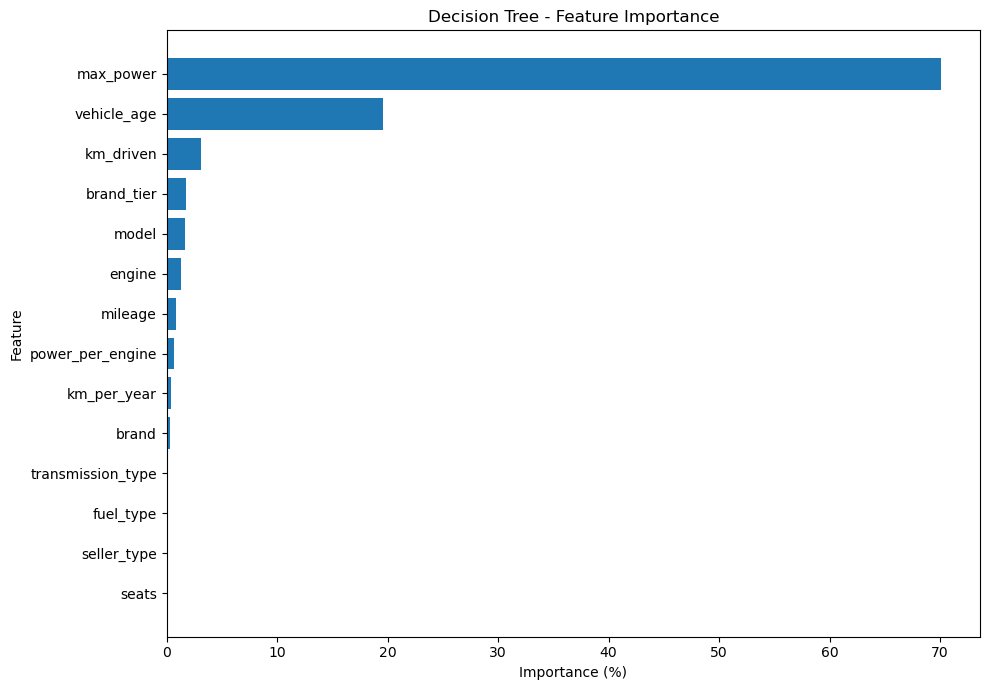

In [29]:
print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Importance": tree.feature_importances_
})

# Convert encoded feature names to original column names
def get_original_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]

    for col in sorted(categorical_features, key=len, reverse=True):
        if name == col or name.startswith(col + "_"):
            return col

    return name


importance_df["Feature"] = (
    importance_df["Encoded_Feature"].apply(get_original_feature)
)

# Combine One-Hot encoded features belonging to the same column
importance_df = (
    importance_df.groupby("Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

importance_df["Importance_Percent"] = (
    importance_df["Importance"] * 100
)

print(importance_df.round(4).to_string(index=False))

importance_df.to_csv(
    DATA_PATH.with_name("decision_tree_feature_importance.csv"),
    index=False
)

# Plot feature importance
plt.figure(figsize=(10, 7))

top_features = importance_df.head(15).sort_values("Importance")

plt.barh(
    top_features["Feature"],
    top_features["Importance_Percent"]
)

plt.xlabel("Importance (%)")
plt.ylabel("Feature")
plt.title("Decision Tree - Feature Importance")
plt.tight_layout()

plt.savefig(
    DATA_PATH.with_name("decision_tree_feature_importance.png"),
    dpi=200
)
plt.show()




PERMUTATION IMPORTANCE
          Feature  Importance_Mean  Importance_Std
        max_power       371573.520        8766.768
      vehicle_age       187191.788        3945.105
           engine        68738.989        1365.907
       brand_tier        28298.610        2883.605
            model        17398.749         367.534
          mileage        11930.287        1306.718
        km_driven        10874.067        2738.684
 power_per_engine         9965.166         638.399
        fuel_type         7137.269         651.513
      km_per_year         4350.989         622.801
            brand         3949.687         523.221
transmission_type         3689.289         507.329
      seller_type         1700.321         336.206
            seats          906.571         274.872


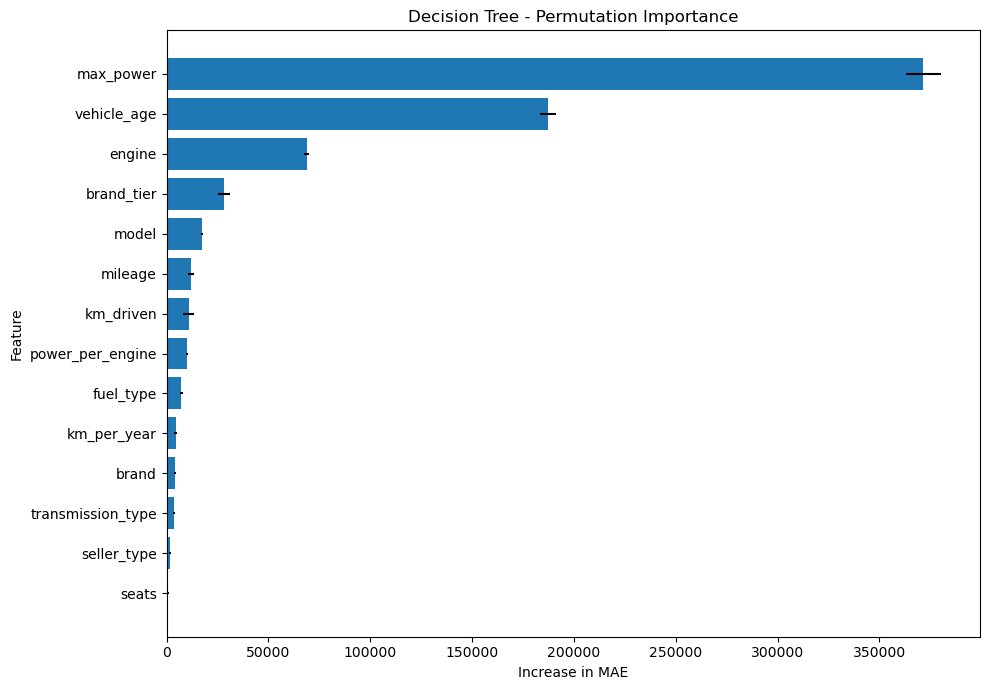

In [30]:
print("\n" + "=" * 60)
print("PERMUTATION IMPORTANCE")
print("=" * 60)

permutation = permutation_importance(
    tree_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation.importances_mean,
    "Importance_Std": permutation.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance_Mean",
    ascending=False
)

print(permutation_df.round(3).to_string(index=False))

permutation_df.to_csv(
    DATA_PATH.with_name("decision_tree_permutation_importance.csv"),
    index=False
)

# Plot permutation importance
top_perm = permutation_df.head(15).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_perm["Feature"],
    top_perm["Importance_Mean"],
    xerr=top_perm["Importance_Std"]
)

plt.xlabel("Increase in MAE")
plt.ylabel("Feature")
plt.title("Decision Tree - Permutation Importance")
plt.tight_layout()

plt.savefig(
    DATA_PATH.with_name("decision_tree_permutation_importance.png"),
    dpi=200
)
plt.show()




DECISION TREE RULES
|--- num__max_power <= 166.15
|   |--- num__max_power <= 88.35
|   |   |--- num__vehicle_age <= 7.50
|   |   |   |--- num__engine <= 1196.50
|   |   |   |   |--- num__engine <= 898.50
|   |   |   |   |   |--- truncated branch of depth 11
|   |   |   |   |--- num__engine >  898.50
|   |   |   |   |   |--- truncated branch of depth 15
|   |   |   |--- num__engine >  1196.50
|   |   |   |   |--- num__vehicle_age <= 4.50
|   |   |   |   |   |--- truncated branch of depth 21
|   |   |   |   |--- num__vehicle_age >  4.50
|   |   |   |   |   |--- truncated branch of depth 21
|   |   |--- num__vehicle_age >  7.50
|   |   |   |--- num__engine <= 1196.50
|   |   |   |   |--- num__vehicle_age <= 11.50
|   |   |   |   |   |--- truncated branch of depth 17
|   |   |   |   |--- num__vehicle_age >  11.50
|   |   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- num__engine >  1196.50
|   |   |   |   |--- num__vehicle_age <= 9.50
|   |   |   |   |   |--- truncated bran

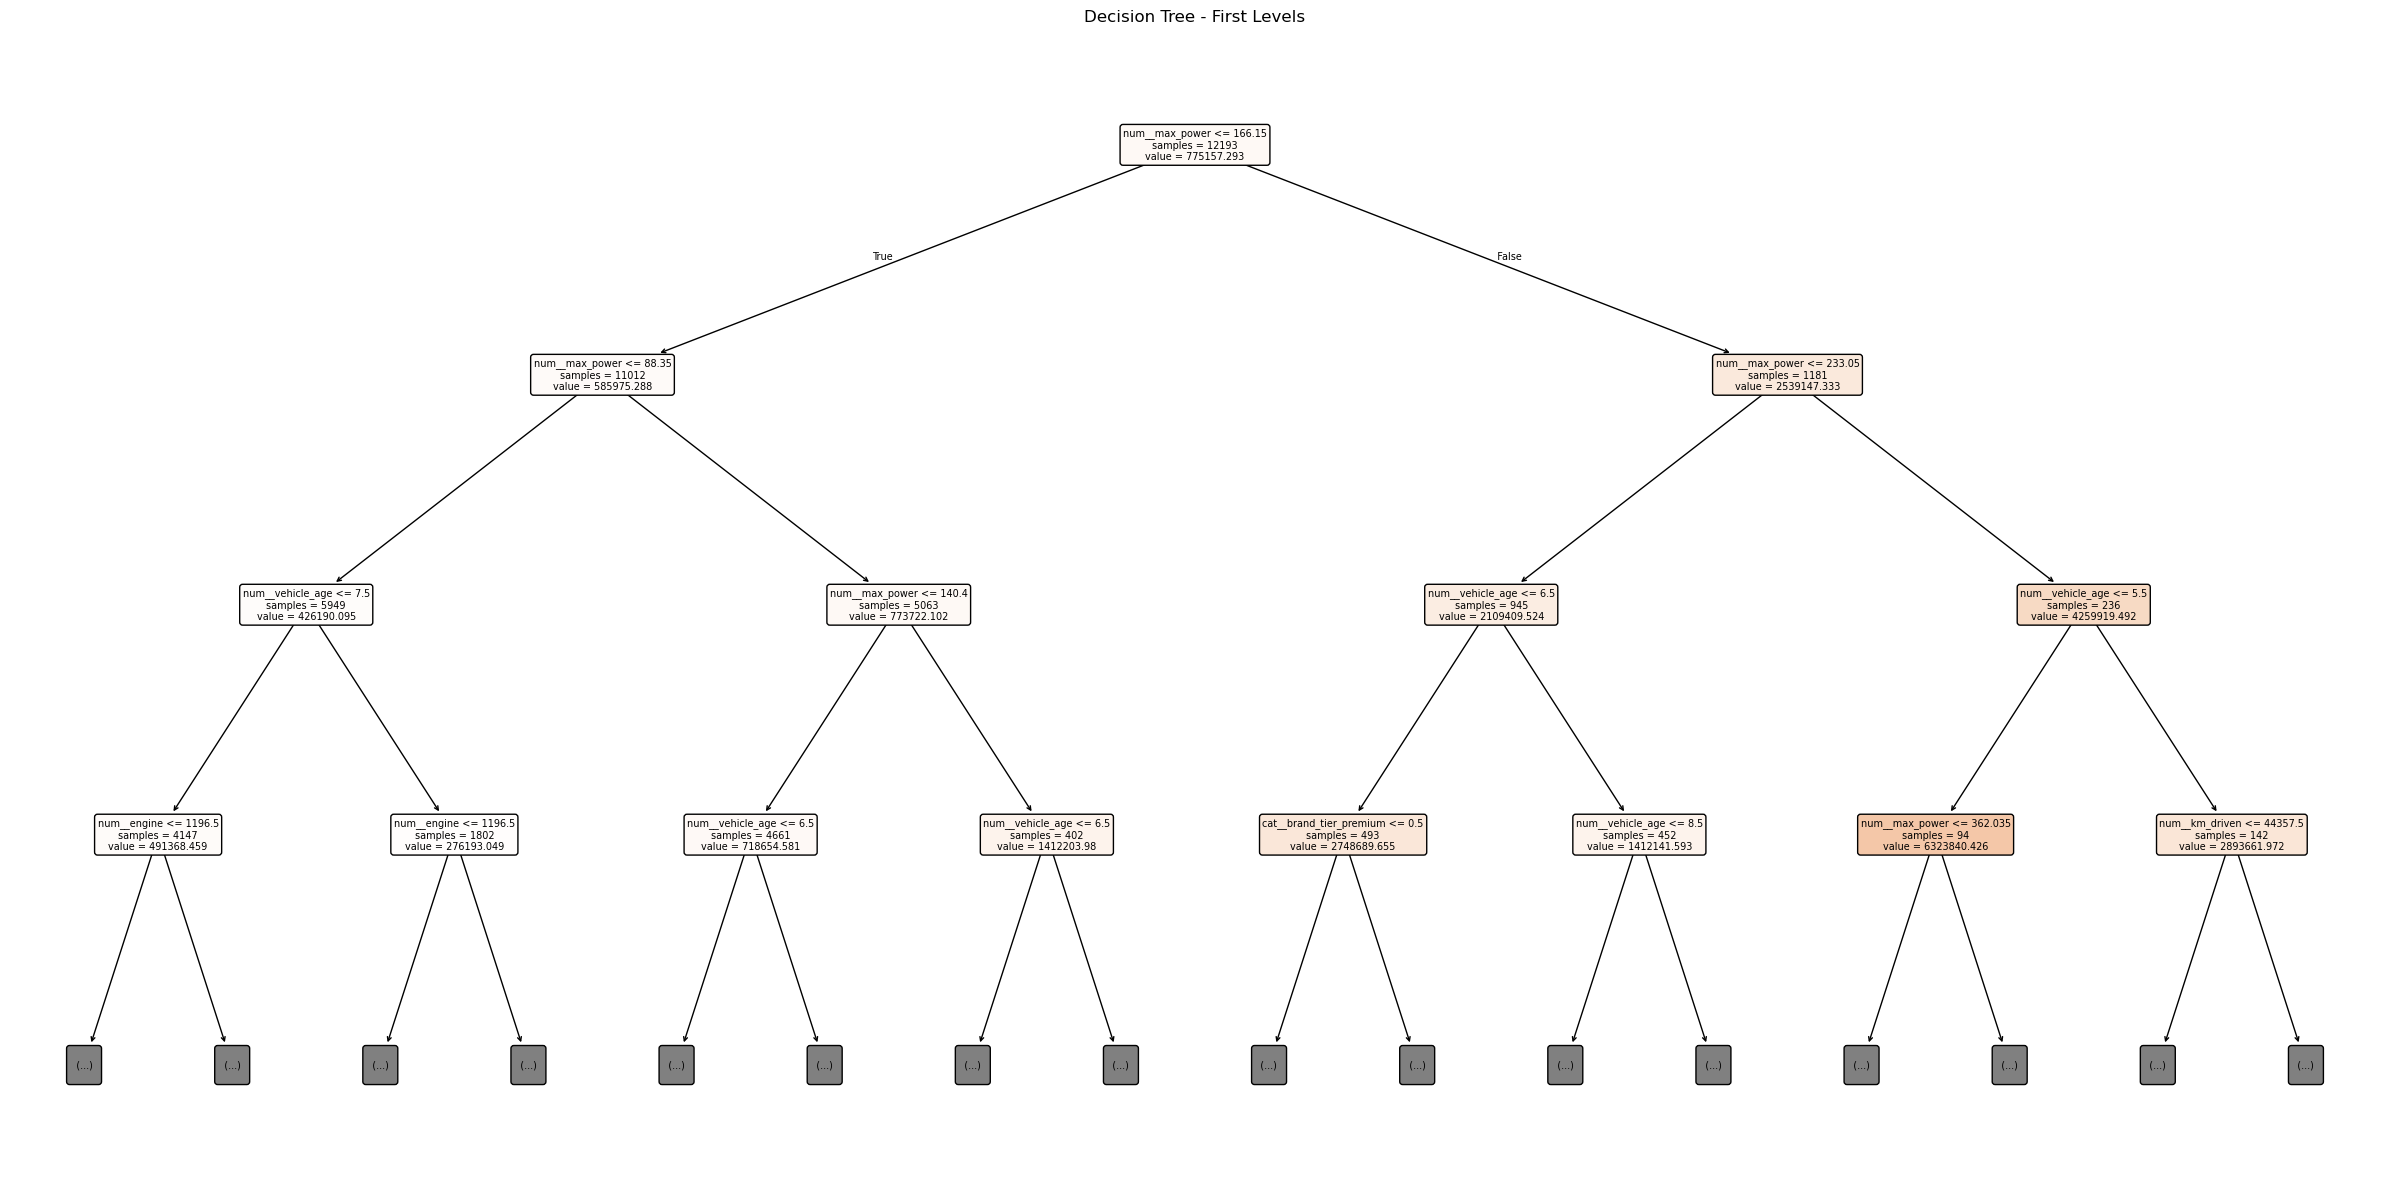

In [31]:
print("\n" + "=" * 60)
print("DECISION TREE RULES")
print("=" * 60)

rules = export_text(
    tree,
    feature_names=list(feature_names),
    max_depth=4,
    decimals=2
)

print(rules)

with open(
    DATA_PATH.with_name("decision_tree_rules.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(rules)


# Visualize the first levels of the tree
plt.figure(figsize=(24, 12))

plot_tree(
    tree,
    feature_names=list(feature_names),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7,
    impurity=False
)

plt.title("Decision Tree - First Levels")
plt.tight_layout()

plt.savefig(
    DATA_PATH.with_name("decision_tree_structure.png"),
    dpi=200
)
plt.show()


ACTUAL VS PREDICTED


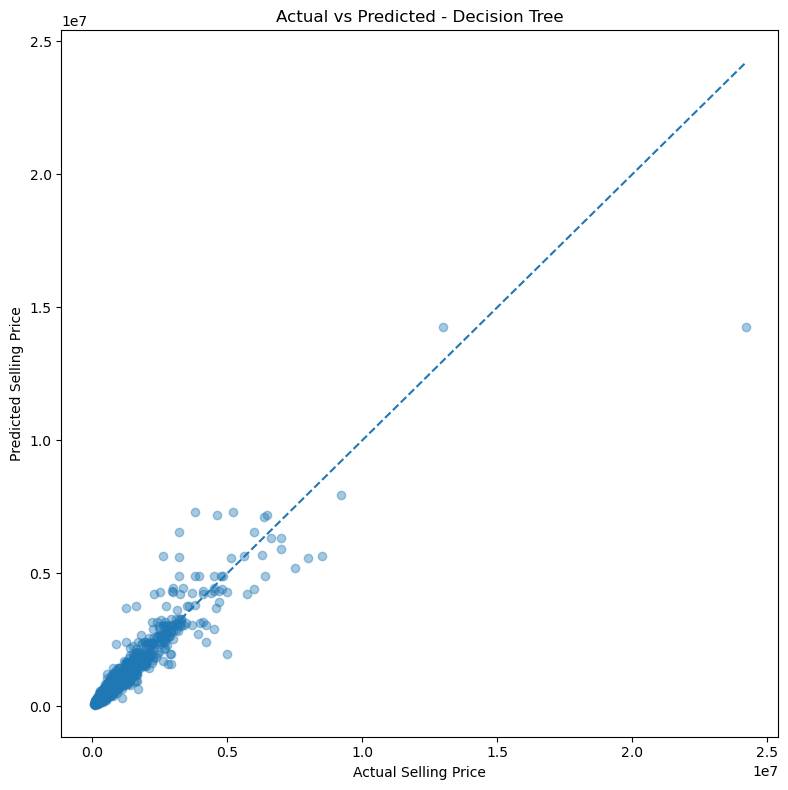

In [32]:
print("\n" + "=" * 60)
print("ACTUAL VS PREDICTED")
print("=" * 60)

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    tree_test_pred,
    alpha=0.4
)

min_value = min(y_test.min(), tree_test_pred.min())
max_value = max(y_test.max(), tree_test_pred.max())

# Perfect prediction line
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted - Decision Tree")

plt.tight_layout()

plt.savefig(
    DATA_PATH.with_name("decision_tree_actual_vs_predicted.png"),
    dpi=200
)
plt.show()




RESIDUAL ANALYSIS
Mean residual: -1901.03
Residual std: 312192.23
Minimum residual: -3500000.0
Maximum residual: 9950000.0


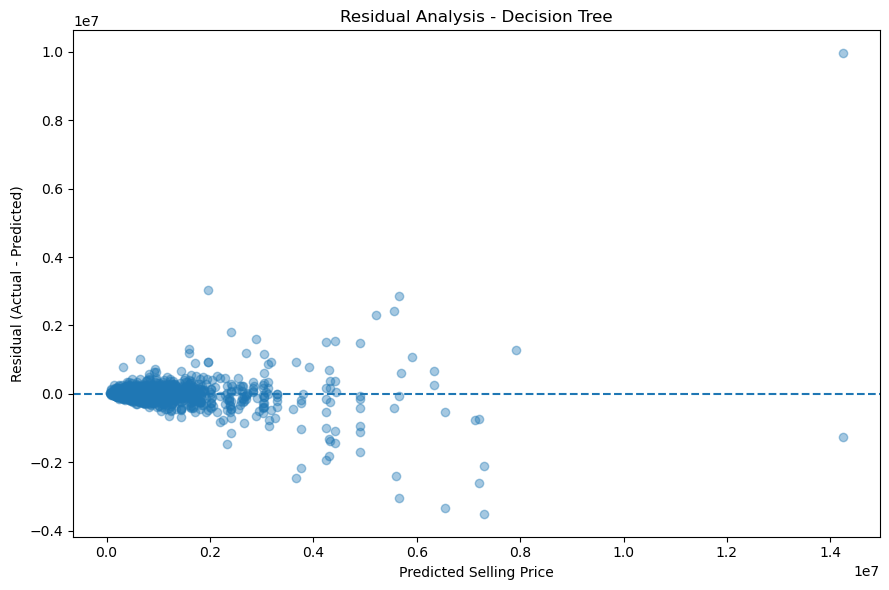

In [33]:
print("\n" + "=" * 60)
print("RESIDUAL ANALYSIS")
print("=" * 60)

residuals = y_test - tree_test_pred

print("Mean residual:", round(residuals.mean(), 2))
print("Residual std:", round(residuals.std(), 2))
print("Minimum residual:", round(residuals.min(), 2))
print("Maximum residual:", round(residuals.max(), 2))

plt.figure(figsize=(9, 6))

plt.scatter(
    tree_test_pred,
    residuals,
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis - Decision Tree")

plt.tight_layout()

plt.savefig(
    DATA_PATH.with_name("decision_tree_residuals.png"),
    dpi=200
)
plt.show()


In [34]:
print("\n" + "=" * 60)
print("LARGEST PREDICTION ERRORS")
print("=" * 60)

error_df = pd.DataFrame({
    "Actual_Price": y_test,
    "Predicted_Price": tree_test_pred
}, index=y_test.index)

error_df["Residual"] = (
    error_df["Actual_Price"] - error_df["Predicted_Price"]
)

error_df["Absolute_Error"] = error_df["Residual"].abs()

error_df["Percentage_Error"] = (
    error_df["Absolute_Error"] /
    error_df["Actual_Price"].replace(0, np.nan) * 100
)

error_df = error_df.sort_values(
    "Absolute_Error",
    ascending=False
)

print(error_df.head(15).round(2).to_string())

error_df.to_csv(
    DATA_PATH.with_name("decision_tree_prediction_errors.csv")
)


LARGEST PREDICTION ERRORS
       Actual_Price  Predicted_Price    Residual  Absolute_Error  Percentage_Error
10869      24200000      14250000.00  9950000.00      9950000.00             41.12
5563        3800000       7300000.00 -3500000.00      3500000.00             92.11
2746        3200000       6537500.00 -3337500.00      3337500.00            104.30
111         2600000       5653571.43 -3053571.43      3053571.43            117.45
7401        5000000       1961285.71  3038714.29      3038714.29             60.77
3087        8500000       5653571.43  2846428.57      2846428.57             33.49
970         4600000       7199000.00 -2599000.00      2599000.00             56.50
6216        1228000       3673333.33 -2445333.33      2445333.33            199.13
14021       8000000       5564285.71  2435714.29      2435714.29             30.45
12960       3200000       5595571.43 -2395571.43      2395571.43             74.86
10274       7500000       5207142.86  2292857.14      229285

In [35]:
print("\n" + "=" * 60)
print("ERROR ANALYSIS BY PRICE RANGE")
print("=" * 60)

price_error_df = error_df.copy()

price_error_df["Price_Group"] = pd.qcut(
    price_error_df["Actual_Price"],
    q=4,
    duplicates="drop"
)

price_analysis = price_error_df.groupby(
    "Price_Group",
    observed=False
).agg(
    Number_of_Cars=("Absolute_Error", "count"),
    MAE=("Absolute_Error", "mean"),
    Median_Error=("Absolute_Error", "median"),
    Mean_Actual_Price=("Actual_Price", "mean")
).reset_index()

print(price_analysis.round(2).to_string(index=False))

price_analysis.to_csv(
    DATA_PATH.with_name("decision_tree_error_by_price_range.csv"),
    index=False
)


print("\n" + "=" * 60)
print("DECISION TREE ANALYSIS COMPLETED")
print("=" * 60)



ERROR ANALYSIS BY PRICE RANGE
           Price_Group  Number_of_Cars       MAE  Median_Error  Mean_Actual_Price
 (59999.999, 390000.0]             773  47011.38       35875.0          283566.62
  (390000.0, 570000.0]             762  66379.71       53625.0          478339.90
  (570000.0, 810000.0]             752  81424.45       63500.0          677886.97
(810000.0, 24200000.0]             762 263407.34      125000.0         1657905.51

DECISION TREE ANALYSIS COMPLETED
